# Lab histogram distance

This notebook computes one of the five scores: how much the color mix inside a building changed between the pre- and post-event images. The images are converted to the Lab color space, and only `a` (green to red) and `b` (blue to yellow) are used. Lightness is left out, since viewing angle and sun elevation change between the two dates and mostly affect brightness.

For each building, the `a` and `b` values of each date are counted into histograms, and the two dates are compared. A histogram does not depend on where a color sits inside the polygon, so a small shift between the dates changes the score very little. A higher score means a larger change.

The score is computed on the same 13 practice pairs as the other four scores. Mexico City and Palu are not used.

## Shared setup

Paths, output folders and the shared practice subset. The notebook is run from `src/`, and `XVIEW2_ROOT` can point to a different dataset folder.

In [21]:
import os
import csv
import json
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

DATA = Path(os.environ.get("XVIEW2_ROOT", "../../Dataset/train"))
IMAGE_DIR = DATA / "images"
LABEL_DIR = DATA / "labels"

OUT = Path("../outputs/lab_histogram")
TABLE_DIR = OUT / "progress" / "tables"
FIGURE_DIR = OUT / "progress" / "figures"
for folder in [TABLE_DIR, FIGURE_DIR, OUT / "final" / "tables", OUT / "final" / "figures"]:
    folder.mkdir(parents=True, exist_ok=True)

SUBSET = [
    "santa-rosa-wildfire_00000006",
    "santa-rosa-wildfire_00000007",
    "santa-rosa-wildfire_00000011",
    "santa-rosa-wildfire_00000002",
    "socal-fire_00000081",
    "socal-fire_00000082",
    "socal-fire_00000090",
    "socal-fire_00000002",
    "midwest-flooding_00000143",
    "midwest-flooding_00000001",
    "midwest-flooding_00000003",
    "guatemala-volcano_00000025",
    "guatemala-volcano_00000006",
]

## Shared preprocessing

These functions are copied unchanged from `correlation_loss.ipynb`, so that this score sees exactly the same pixels as the other four. They match the colors of the post-event image to the pre-event image, find a shift of at most 4 pixels for each building, and erode each polygon by one pixel. The explanations are in that notebook.

In [22]:
def luminance(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def local_std(gray, window=5):
    values = gray.astype(np.float64)
    mean = cv2.blur(values, (window, window))
    second = cv2.blur(values * values, (window, window))
    variance = np.maximum(second - mean * mean, 0.0)
    return np.sqrt(variance)


def usable_pixels(image):
    gray = luminance(image)
    dark = gray < 40
    smooth = local_std(gray) < 8
    return ~(dark & smooth)


def match_channel(source, reference, source_keep, reference_keep):
    source_hist = np.bincount(source[source_keep], minlength=256).astype(np.float64)
    reference_hist = np.bincount(reference[reference_keep], minlength=256).astype(np.float64)
    if source_hist.sum() == 0 or reference_hist.sum() == 0:
        return source.copy()
    source_cdf = np.cumsum(source_hist) / source_hist.sum()
    reference_cdf = np.cumsum(reference_hist) / reference_hist.sum()
    lookup = np.searchsorted(reference_cdf, source_cdf, side="left")
    lookup = np.clip(lookup, 0, 255).astype(np.uint8)
    return lookup[source]


def histogram_match(post, pre):
    source_keep = usable_pixels(post)
    reference_keep = usable_pixels(pre)
    matched = np.empty_like(post)
    for channel in range(3):
        matched[:, :, channel] = match_channel(
            post[:, :, channel],
            pre[:, :, channel],
            source_keep,
            reference_keep,
        )
    return matched


def polygon_points(wkt):
    start = wkt.find("((")
    end = wkt.rfind("))")
    body = wkt[start + 2:end]
    points = []
    for piece in body.split(","):
        parts = piece.split()
        points.append([float(parts[0]), float(parts[1])])
    return np.asarray(points, dtype=np.float64)


def short_side(points):
    width = float(points[:, 0].max() - points[:, 0].min())
    height = float(points[:, 1].max() - points[:, 1].min())
    return min(width, height)


def best_shift(pre_gray, post_gray, points):
    if short_side(points) < 12:
        return 0, 0
    height, width = pre_gray.shape
    x0 = max(0, int(np.floor(points[:, 0].min())))
    y0 = max(0, int(np.floor(points[:, 1].min())))
    x1 = min(width, int(np.ceil(points[:, 0].max())) + 1)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + 1)
    if x1 - x0 < 2 or y1 - y0 < 2:
        return 0, 0
    template = pre_gray[y0:y1, x0:x1]
    if float(template.std()) < 1.0:
        return 0, 0
    search_x0 = max(0, x0 - 4)
    search_y0 = max(0, y0 - 4)
    search_x1 = min(width, x1 + 4)
    search_y1 = min(height, y1 + 4)
    search = post_gray[search_y0:search_y1, search_x0:search_x1]
    if search.shape[0] < template.shape[0] or search.shape[1] < template.shape[1]:
        return 0, 0
    scores = cv2.matchTemplate(search, template, cv2.TM_CCOEFF_NORMED)
    if not np.isfinite(scores).any():
        return 0, 0
    scores = np.nan_to_num(scores, nan=-1.0)
    _, _, _, peak = cv2.minMaxLoc(scores)
    dx = int(np.clip(peak[0] - (x0 - search_x0), -4, 4))
    dy = int(np.clip(peak[1] - (y0 - search_y0), -4, 4))
    return dx, dy


def polygon_mask(points, shape):
    mask = np.zeros(shape, dtype=np.uint8)
    contour = np.round(points).astype(np.int32)
    cv2.fillPoly(mask, [contour], 1)
    return mask


def interior_mask(points, shape):
    mask = polygon_mask(points, shape)
    eroded = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=1)
    if int(eroded.sum()) < 40:
        return mask
    return eroded


def paired_values(pre_gray, post_gray, mask, dx, dy):
    rows, cols = np.nonzero(mask)
    shifted_rows = rows + dy
    shifted_cols = cols + dx
    height, width = pre_gray.shape
    keep = (
        (shifted_rows >= 0)
        & (shifted_rows < height)
        & (shifted_cols >= 0)
        & (shifted_cols < width)
    )
    rows = rows[keep]
    cols = cols[keep]
    shifted_rows = shifted_rows[keep]
    shifted_cols = shifted_cols[keep]
    return pre_gray[rows, cols], post_gray[shifted_rows, shifted_cols]


def load_pair(image_id):
    pre = cv2.imread(str(IMAGE_DIR / f"{image_id}_pre_disaster.png"), cv2.IMREAD_COLOR)
    post = cv2.imread(str(IMAGE_DIR / f"{image_id}_post_disaster.png"), cv2.IMREAD_COLOR)
    if pre is None or post is None:
        raise FileNotFoundError(image_id)
    label_path = LABEL_DIR / f"{image_id}_post_disaster.json"
    label = json.loads(label_path.read_text())
    return pre, post, label["features"]["xy"]

## The score

OpenCV stores `a` and `b` as values from 0 to 255, where 128 means no color. For one building, the `a` values of each date are counted into 8 bins and divided by the number of pixels, and the same is done for `b`. The pre- and post-event histograms are compared with the chi-square distance

$$
\chi^2(p, q) = \frac{1}{2} \sum_i \frac{(p_i - q_i)^2}{p_i + q_i},
$$

which is 0 for identical histograms and 1 for histograms with no bin in common. Bins that are empty in both are skipped. The distances for `a` and `b` are combined as $\sqrt{d_a^2 + d_b^2}$, so a strong change in one channel counts more than the same change spread over both. The score lies between 0 and $\sqrt{2}$.

In [23]:
LAB_RANGE = (0, 256)  # placeholder; the scoring cell replaces it with the range of the data
LAB_BINS = 8


def histogram(values):
    counts, _ = np.histogram(values, bins=LAB_BINS, range=LAB_RANGE)
    return counts / counts.sum()


def chi_square(p, q):
    used = (p + q) > 0
    return 0.5 * np.sum((p[used] - q[used]) ** 2 / (p[used] + q[used]))


def lab_score(pre_ab, post_ab):
    d_a = chi_square(histogram(pre_ab[:, 0]), histogram(post_ab[:, 0]))
    d_b = chi_square(histogram(pre_ab[:, 1]), histogram(post_ab[:, 1]))
    return float(np.sqrt(d_a ** 2 + d_b ** 2))


test = np.array([[120, 140], [130, 150], [128, 128]])
print("identical patches score:", lab_score(test, test))

identical patches score: 0.0


## Scoring the subset

Each pair is color-matched once. For every classified building, the polygon is eroded, the shift is found on luminance as in the other scores, and the `a` and `b` values inside the polygon are taken from both dates. The damage label is stored for the figures but is not used by the score.

In [24]:
rows = []
for image_id in SUBSET:
    pre, post, buildings = load_pair(image_id)
    matched = histogram_match(post, pre)
    pre_gray, post_gray = luminance(pre), luminance(matched)
    pre_lab = cv2.cvtColor(pre, cv2.COLOR_BGR2LAB)
    post_lab = cv2.cvtColor(matched, cv2.COLOR_BGR2LAB)

    for b in buildings:
        subtype = b["properties"]["subtype"]
        points = polygon_points(b["wkt"])
        if subtype == "un-classified" or len(points) < 3:
            continue
        mask = interior_mask(points, pre_gray.shape)
        if mask.sum() == 0:
            continue
        dx, dy = best_shift(pre_gray, post_gray, points)

        # paired_values takes one channel at a time: index 1 is a, index 2 is b
        pre_a, post_a = paired_values(pre_lab[:, :, 1], post_lab[:, :, 1], mask, dx, dy)
        pre_b, post_b = paired_values(pre_lab[:, :, 2], post_lab[:, :, 2], mask, dx, dy)
        if pre_a.size == 0:
            continue
        pre_ab = np.column_stack([pre_a, pre_b])
        post_ab = np.column_stack([post_a, post_b])

        rows.append({"image_id": image_id, "building_id": b["properties"]["uid"],
                     "n_pixels": len(pre_a),
                     "subtype": subtype, "dx": dx, "dy": dy, "points": points,
                     "pre_ab": pre_ab, "post_ab": post_ab})

# set the bin range from the 1st and 99th percentiles of this practice set
all_values = np.concatenate([np.concatenate([r["pre_ab"], r["post_ab"]]) for r in rows])
low = int(np.percentile(all_values, 1, axis=0).min())
high = int(np.percentile(all_values, 99, axis=0).max()) + 1
LAB_RANGE = (low, high)
print("LAB_RANGE:", LAB_RANGE)

for r in rows:
    r["score"] = lab_score(r["pre_ab"], r["post_ab"])

table = pd.DataFrame(rows)
table["event"] = table["image_id"].str.rsplit("_", n=1).str[0]
table[["image_id", "building_id", "score", "n_pixels"]].to_csv(
    TABLE_DIR / "lab_histogram_subset.csv", index=False, float_format="%.6f")
print(len(table), "buildings scored")

LAB_RANGE: (111, 150)
878 buildings scored


## Checking the bins

Roof colors sit close to gray (128), so with 8 bins over 0–255 all pixels fell into the two central bins. The range is therefore taken from the 1st–99th percentiles of the data, which gives (111, 150) on this subset. It is chosen from the spread of the values, not from the F1. Values outside the range go into the first or last bin.

The narrower bins make the score more sensitive to slight color casts, which explains some high scores on intact roofs in the Guatemala volcano pairs.

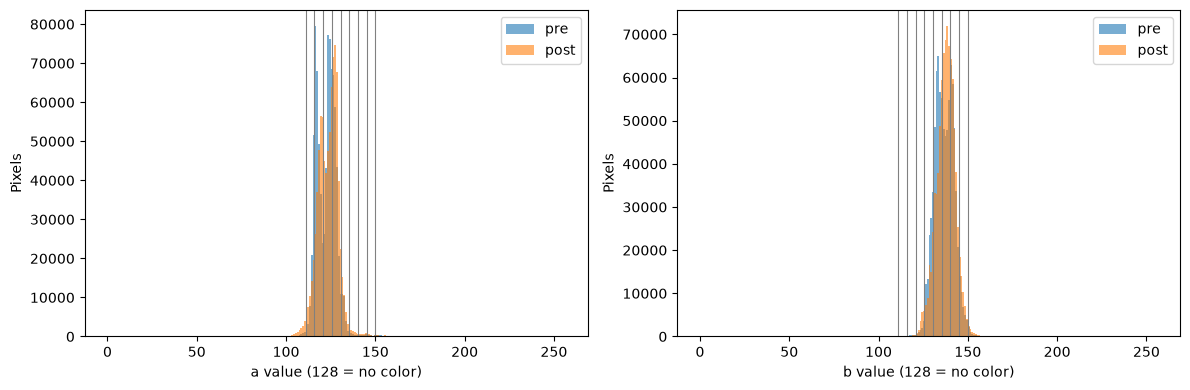

pre-event pixels in the two central bins: a 26.1%, b 45.4%
no-damage: 687 buildings, 4.1% score below 0.05
destroyed: 169 buildings, 0.0% score below 0.05


In [25]:
edges = np.linspace(LAB_RANGE[0], LAB_RANGE[1], LAB_BINS + 1)
all_pre = np.concatenate(table["pre_ab"].values)
all_post = np.concatenate(table["post_ab"].values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, channel, name in zip(axes, [0, 1], ["a", "b"]):
    ax.hist(all_pre[:, channel], bins=256, range=(0, 256), alpha=0.6, label="pre")
    ax.hist(all_post[:, channel], bins=256, range=(0, 256), alpha=0.6, label="post")
    for edge in edges:
        ax.axvline(edge, color="gray", linewidth=0.8)
    ax.set_xlabel(f"{name} value (128 = no color)")
    ax.set_ylabel("Pixels")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "bin_check.png", dpi=160)
plt.show()

central = (all_pre >= edges[3]) & (all_pre < edges[5])
print(f"pre-event pixels in the two central bins: a {central[:, 0].mean():.1%}, b {central[:, 1].mean():.1%}")
for subtype in ["no-damage", "destroyed"]:
    scores = table.loc[table["subtype"] == subtype, "score"]
    print(f"{subtype}: {len(scores)} buildings, {(scores < 0.05).mean():.1%} score below 0.05")

## Example buildings

Each row shows one building: the pre-event image, the post-event image after color matching and the shift, and the `a` and `b` histograms of both dates, which are what the score compares. The first figure shows the two highest-scoring destroyed buildings from different events. The second shows the lowest- and highest-scoring undamaged buildings.

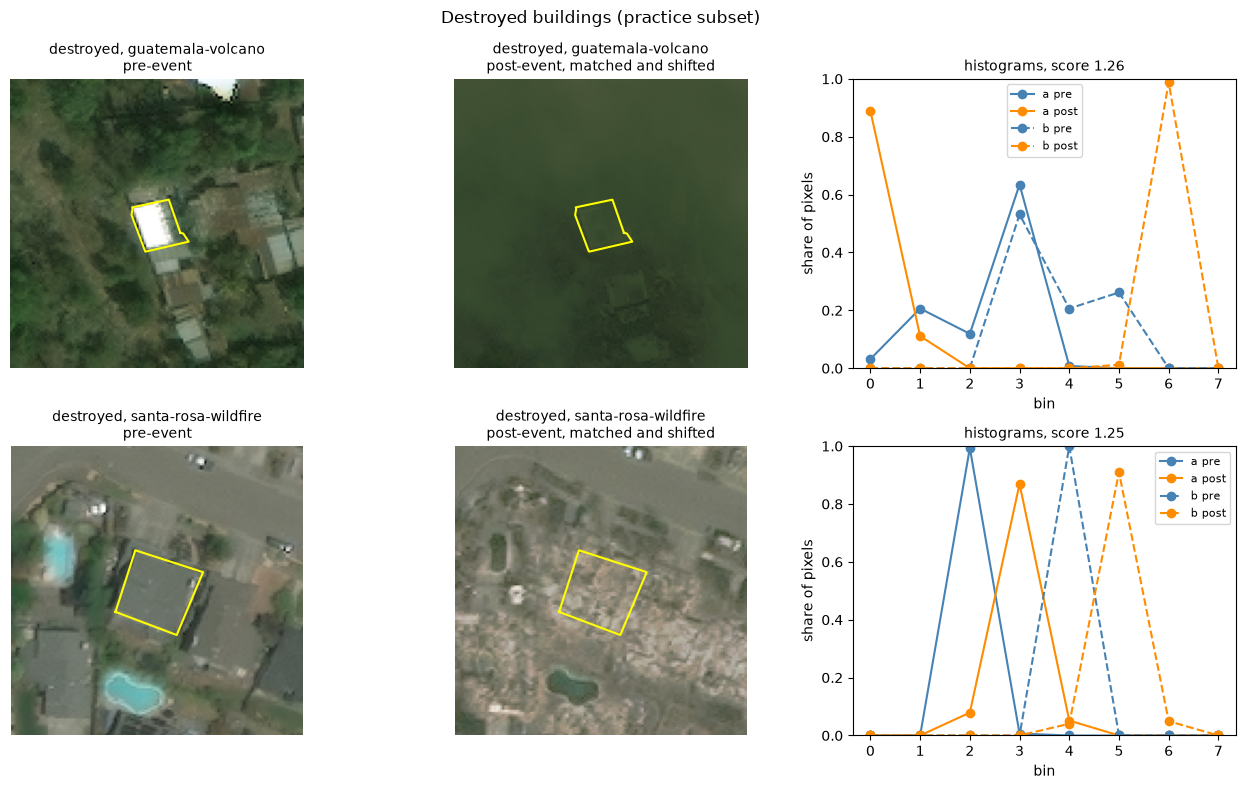

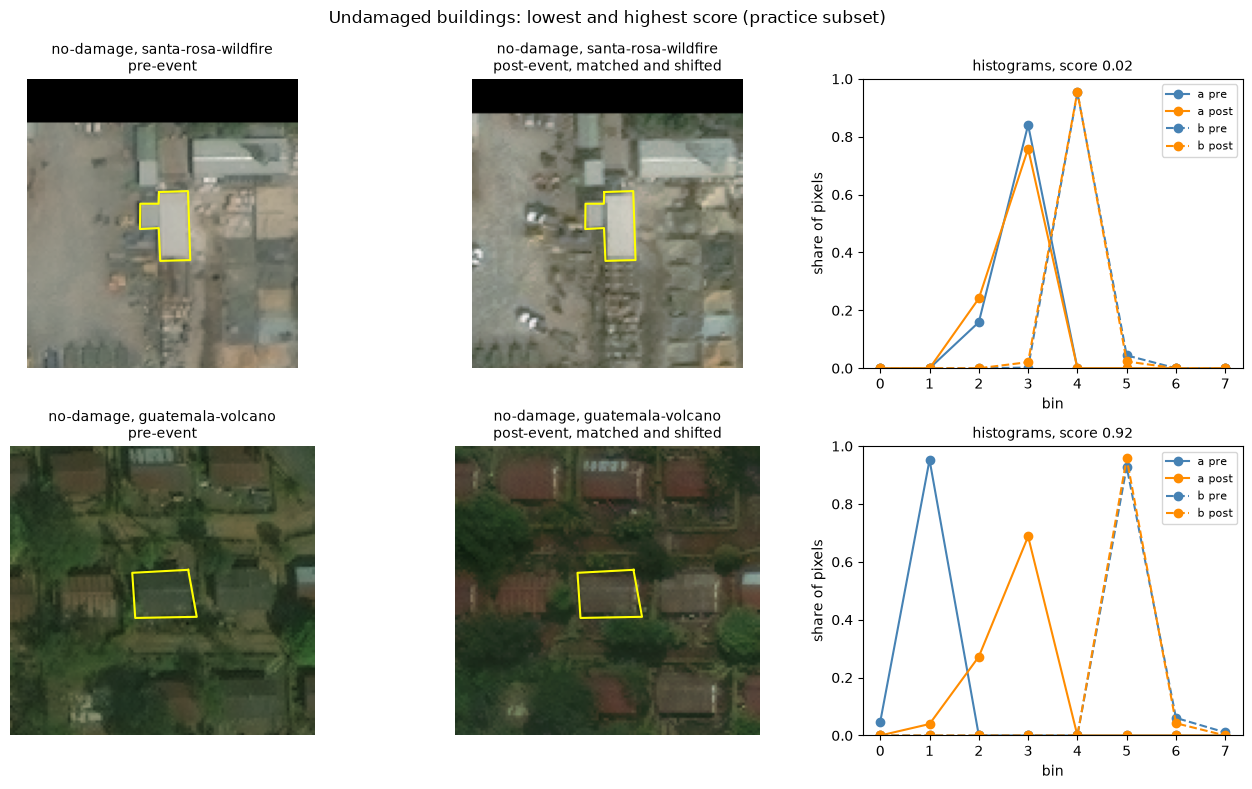

In [26]:
def crop(image, points, dx=0, dy=0, margin=48):
    x0, y0 = (points.min(axis=0) - margin).astype(int)
    x1, y1 = (points.max(axis=0) + margin).astype(int)
    return image[y0 + dy:y1 + dy, x0 + dx:x1 + dx], x0, y0


def show_examples(examples, title, filename):
    fig, axes = plt.subplots(len(examples), 3, figsize=(13, 4 * len(examples)))
    for row_axes, ex in zip(axes, examples):
        pre, post, _ = load_pair(ex["image_id"])
        matched = histogram_match(post, pre)
        pts = ex["points"]

        for ax, image, shift, label in [(row_axes[0], pre, (0, 0), "pre-event"),
                                        (row_axes[1], matched, (ex["dx"], ex["dy"]), "post-event, matched and shifted")]:
            part, x0, y0 = crop(image, pts, *shift)
            ax.imshow(part[:, :, ::-1])
            ax.plot(np.append(pts[:, 0], pts[0, 0]) - x0, np.append(pts[:, 1], pts[0, 1]) - y0, color="yellow")
            ax.set_title(f"{ex['subtype']}, {ex['event']}\n{label}", fontsize=10)
            ax.axis("off")

        ax = row_axes[2]
        for channel, name, style in [(0, "a", "-"), (1, "b", "--")]:
            ax.plot(histogram(ex["pre_ab"][:, channel]), style, color="steelblue", marker="o", label=f"{name} pre")
            ax.plot(histogram(ex["post_ab"][:, channel]), style, color="darkorange", marker="o", label=f"{name} post")
        ax.set_ylim(0, 1)
        ax.set_xlabel("bin")
        ax.set_ylabel("share of pixels")
        ax.set_title(f"histograms, score {ex['score']:.2f}", fontsize=10)
        ax.legend(fontsize=8)

    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=160)
    plt.show()


# buildings large enough to see, and far enough from the image edge to crop
corners_min = table["points"].apply(lambda p: p.min())
corners_max = table["points"].apply(lambda p: p.max())
visible = table[(table["n_pixels"] >= 250) & (corners_min >= 52) & (corners_max <= 972)]

destroyed = visible[visible["subtype"] == "destroyed"].sort_values("score", ascending=False)
first = destroyed.iloc[0]
others = destroyed[destroyed["event"] != first["event"]]
second = others.iloc[0] if len(others) else destroyed.iloc[1]
show_examples([first, second], "Destroyed buildings (practice subset)", "examples_destroyed.png")

intact = visible[visible["subtype"] == "no-damage"].sort_values("score")
show_examples([intact.iloc[0], intact.iloc[-1]], "Undamaged buildings: lowest and highest score (practice subset)",
              "examples_intact.png")

## Scores by class and by event

The box plot shows the score for each damage class. Minor and major damage are rare in this subset, so those two boxes are only descriptive. The histogram compares undamaged and destroyed buildings, and the bar chart shows the mean score of both classes for each practice event.

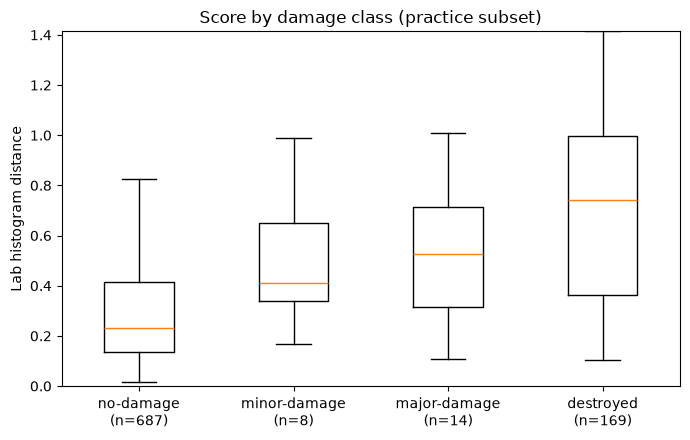

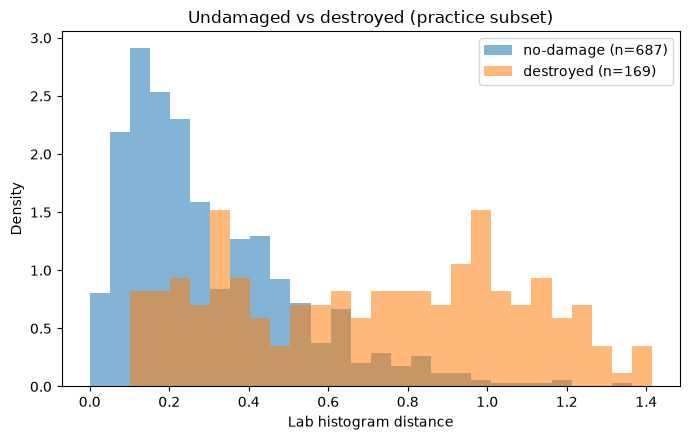

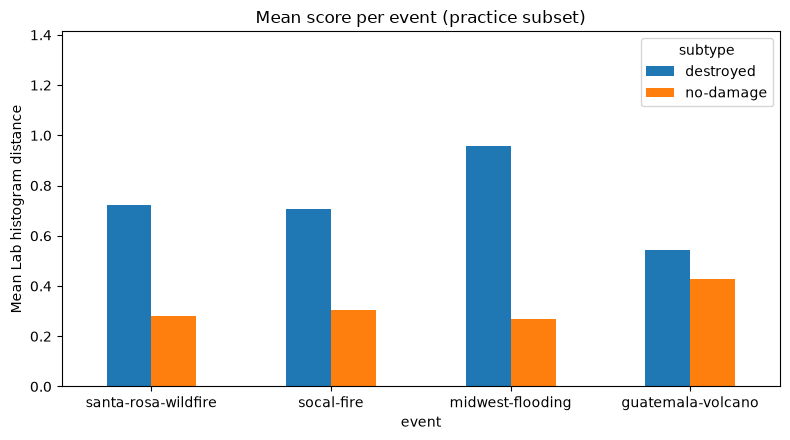

In [27]:
SCORE_MAX = np.sqrt(2)
classes = ["no-damage", "minor-damage", "major-damage", "destroyed"]
events = list(dict.fromkeys(table["event"]))

plt.figure(figsize=(7, 4.5))
plt.boxplot([table.loc[table["subtype"] == c, "score"] for c in classes], showfliers=False)
plt.xticks(range(1, 5), [f"{c}\n(n={(table['subtype'] == c).sum()})" for c in classes])
plt.ylim(0, SCORE_MAX)
plt.ylabel("Lab histogram distance")
plt.title("Score by damage class (practice subset)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "score_by_class.png", dpi=160)
plt.show()

plt.figure(figsize=(7, 4.5))
for c in ["no-damage", "destroyed"]:
    scores = table.loc[table["subtype"] == c, "score"]
    plt.hist(scores, bins=np.linspace(0, SCORE_MAX, 29), density=True, alpha=0.55, label=f"{c} (n={len(scores)})")
plt.xlabel("Lab histogram distance")
plt.ylabel("Density")
plt.legend()
plt.title("Undamaged vs destroyed (practice subset)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "score_histogram.png", dpi=160)
plt.show()

by_event = (table[table["subtype"].isin(["no-damage", "destroyed"])]
            .pivot_table(index="event", columns="subtype", values="score", aggfunc="mean")
            .reindex(events))
ax = by_event.plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylim(0, SCORE_MAX)
ax.set_ylabel("Mean Lab histogram distance")
ax.set_title("Mean score per event (practice subset)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "score_by_event.png", dpi=160)
plt.show()

## Partial numbers

The score is turned into a destroyed-versus-rest decision with one threshold, using the same rule as the other scores: the threshold with the highest destroyed F1, among those that keep the false-positive rate on undamaged buildings at or below 0.25. Thresholds are tried in steps of 0.005. This cut is provisional and is not used on Mexico City or Palu.

The metrics file uses the same lines as the other scores, since `progress_comparison.ipynb` reads it line by line.

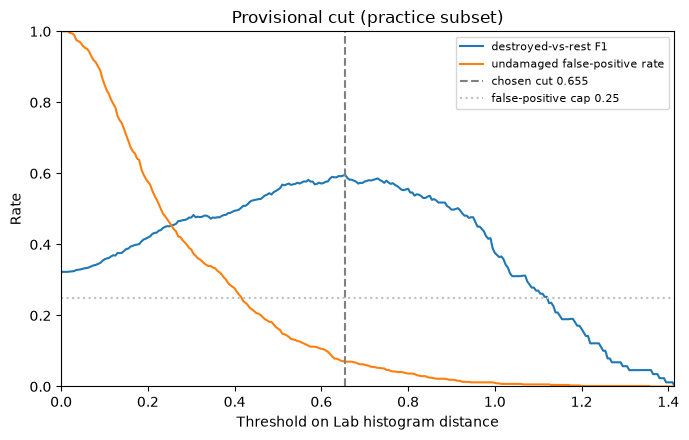

class, n, mean, median
no-damage, 687, 0.2980, 0.2297
minor-damage, 8, 0.5008, 0.4123
major-damage, 14, 0.5131, 0.5246
destroyed, 169, 0.7071, 0.7403
event, no-damage n, no-damage mean, destroyed n, destroyed mean
santa-rosa-wildfire, 208, 0.2800, 116, 0.7238
socal-fire, 61, 0.3059, 26, 0.7063
midwest-flooding, 321, 0.2688, 6, 0.9577
guatemala-volcano, 97, 0.4280, 21, 0.5442
threshold, 0.655, destroyed_f1, 0.5956, precision, 0.6333, recall, 0.5621
undamaged_false_positive_rate, 0.0699, tp, 95, fp, 55, fn, 74
subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.


In [28]:
scores = table["score"].values
is_destroyed = (table["subtype"] == "destroyed").values
is_undamaged = (table["subtype"] == "no-damage").values

cuts = np.round(np.arange(0, SCORE_MAX + 0.005, 0.005), 3)
f1s, rates = [], []
best = None
for cut in cuts:
    predicted = scores >= cut
    tp = int(np.sum(predicted & is_destroyed))
    fp = int(np.sum(predicted & ~is_destroyed))
    fn = int(np.sum(~predicted & is_destroyed))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rate = float(predicted[is_undamaged].mean())
    f1s.append(f1)
    rates.append(rate)
    # keep the best F1 under the cap; on ties, the lower false-positive rate
    if rate <= 0.25 and (best is None or (f1, -rate) >= (best["f1"], -best["rate"])):
        best = {"cut": cut, "f1": f1, "precision": precision, "recall": recall,
                "rate": rate, "tp": tp, "fp": fp, "fn": fn}

plt.figure(figsize=(7, 4.5))
plt.plot(cuts, f1s, label="destroyed-vs-rest F1")
plt.plot(cuts, rates, label="undamaged false-positive rate")
plt.axvline(best["cut"], color="gray", linestyle="--", label=f"chosen cut {best['cut']:.3f}")
plt.axhline(0.25, color="silver", linestyle=":", label="false-positive cap 0.25")
plt.xlim(0, SCORE_MAX)
plt.ylim(0, 1)
plt.xlabel("Threshold on Lab histogram distance")
plt.ylabel("Rate")
plt.legend(fontsize=8)
plt.title("Provisional cut (practice subset)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "threshold_curve.png", dpi=160)
plt.show()

lines = ["class, n, mean, median"]
for c in classes:
    s = table.loc[table["subtype"] == c, "score"]
    lines.append(f"{c}, {len(s)}, {s.mean():.4f}, {s.median():.4f}" if len(s) else f"{c}, 0, , ")
lines.append("event, no-damage n, no-damage mean, destroyed n, destroyed mean")
for e in events:
    nd = table.loc[(table["event"] == e) & (table["subtype"] == "no-damage"), "score"]
    de = table.loc[(table["event"] == e) & (table["subtype"] == "destroyed"), "score"]
    nd_mean = f"{nd.mean():.4f}" if len(nd) else ""
    de_mean = f"{de.mean():.4f}" if len(de) else ""
    lines.append(f"{e}, {len(nd)}, {nd_mean}, {len(de)}, {de_mean}")
lines.append(f"threshold, {best['cut']:.3f}, destroyed_f1, {best['f1']:.4f}, "
             f"precision, {best['precision']:.4f}, recall, {best['recall']:.4f}")
lines.append(f"undamaged_false_positive_rate, {best['rate']:.4f}, "
             f"tp, {best['tp']}, fp, {best['fp']}, fn, {best['fn']}")
lines.append("subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.")

(TABLE_DIR / "lab_histogram_metrics.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

## Results and what is left

On the subset, the score reaches a destroyed F1 of 0.60 at an undamaged false-positive rate of 0.07, lower than correlation loss (0.23) and change-vector magnitude (0.16). It is weakest on the Guatemala volcano pairs, where gray ash on gray roofs changes the color mix little and color casts raise the scores of intact roofs. It agrees only weakly with the other four scores (Spearman 0.27–0.35), so it adds information they do not capture.

Still open: the full run on the remaining practice pairs, where the range is recalculated from all practice pairs and then kept fixed for Mexico City and Palu.